   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  

Missing Values:
Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Pra

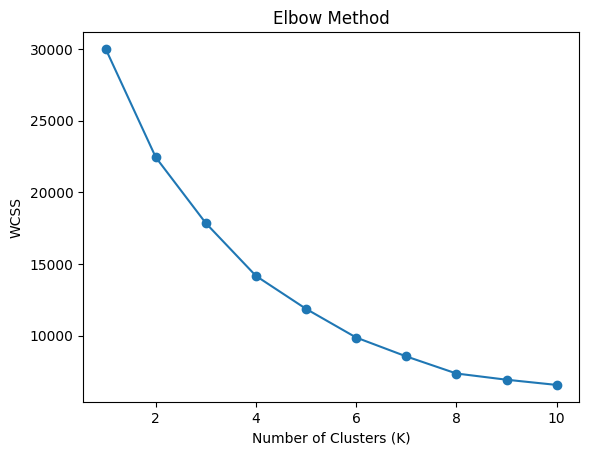

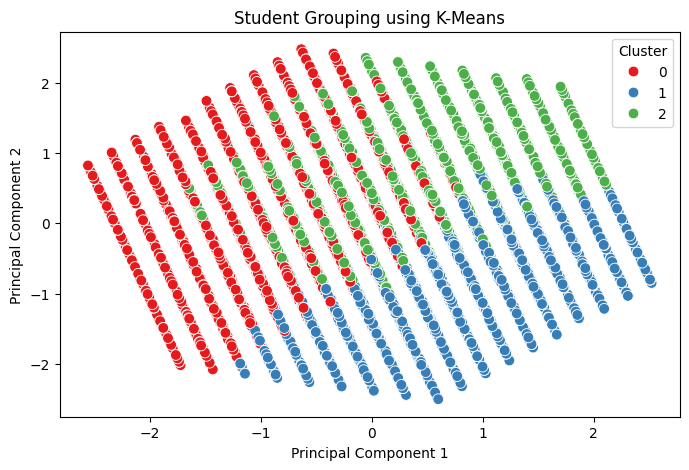


Student Cluster Characteristics:
         Hours Studied  Previous Scores  Sample Question Papers Practiced  \
Cluster                                                                     
0                 2.25            70.21                              4.41   
1                 6.59            53.14                              4.63   
2                 6.67            85.45                              4.74   

         Performance Index  
Cluster                     
0                    48.18  
1                    43.17  
2                    76.29  

Number of Students in Each Cluster:
Cluster
0    3735
1    3191
2    3074
Name: count, dtype: int64


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# 1. Load student dataset
df = pd.read_csv("Student_Performance.csv")
print(df.head())

# 2. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Select three numerical academic features
X = df[[
    "Hours Studied",
    "Previous Scores",
    "Sample Question Papers Practiced"
]]

# 3. Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Apply Elbow Method
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

# Plot Elbow Graph
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# 5. Train K-Means with suitable K
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

df["Cluster"] = clusters

# 6. Reduce three features to two dimensions using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Visualize student clusters
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df["Cluster"],
    palette="Set1",
    s=60
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Student Grouping using K-Means")
plt.show()

# 7. Interpret cluster profiles
print("\nStudent Cluster Characteristics:")
print(df.groupby("Cluster")[[
    "Hours Studied",
    "Previous Scores",
    "Sample Question Papers Practiced",
    "Performance Index"
]].mean().round(2))

# Count students in each cluster
print("\nNumber of Students in Each Cluster:")
print(df["Cluster"].value_counts().sort_index())
